In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mexwell/fake-reviews-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fake-reviews-dataset' dataset.
Path to dataset files: /kaggle/input/fake-reviews-dataset


### Step 1: Download the Dataset
In this cell, the `kagglehub` library is used to download the latest version of the "fake-reviews-dataset" directly from Kaggle. The local file path where the dataset is stored is printed for verification.

In [ ]:
import pandas as pd
import os

pat1 = os.path.join(path, "fake reviews dataset.csv")

df = pd.read_csv(pat1)
df

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...
...,...,...,...,...
40427,Clothing_Shoes_and_Jewelry_5,4.0,OR,I had read some reviews saying that this bra r...
40428,Clothing_Shoes_and_Jewelry_5,5.0,CG,I wasn't sure exactly what it would be. It is ...
40429,Clothing_Shoes_and_Jewelry_5,2.0,OR,"You can wear the hood by itself, wear it with ..."
40430,Clothing_Shoes_and_Jewelry_5,1.0,CG,I liked nothing about this dress. The only rea...


### Step 2: Load the Dataset
Here, the downloaded CSV file path is constructed, and the data is loaded into a Pandas DataFrame (`df`). We then display the loaded data containing product categories, ratings, labels (CG: Computer-Generated, OR: Original/Genuine), and raw text reviews.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB


### Step 3: Dataset Summary
We run `df.info()` to check the data types, non-null value counts, and overall memory usage of our DataFrame. The dataset contains 40,432 entries with no missing data in any of the columns.

In [ ]:
df.isnull().sum()

,0
category,0
rating,0
label,0
text_,0


### Step 4: Missing Value Check
This cell verifies if there are any missing (`NaN`) values in the dataset using `df.isnull().sum()`. The output confirms that all columns are completely filled.

In [ ]:
df.duplicated().sum()

np.int64(12)

### Step 5: Duplicate Detection
We check for identical duplicate rows in the dataset using `df.duplicated().sum()`. The check reveals that there are 12 duplicate records.

In [ ]:
df.drop_duplicates()

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...
...,...,...,...,...
40427,Clothing_Shoes_and_Jewelry_5,4.0,OR,I had read some reviews saying that this bra r...
40428,Clothing_Shoes_and_Jewelry_5,5.0,CG,I wasn't sure exactly what it would be. It is ...
40429,Clothing_Shoes_and_Jewelry_5,2.0,OR,"You can wear the hood by itself, wear it with ..."
40430,Clothing_Shoes_and_Jewelry_5,1.0,CG,I liked nothing about this dress. The only rea...


### Step 6: Removing Duplicates
This step cleans up the dataset by dropping the duplicate rows using `df.drop_duplicates()`, lowering the total count from 40,432 to 40,420.

label
CG    20216
OR    20216
Name: count, dtype: int64


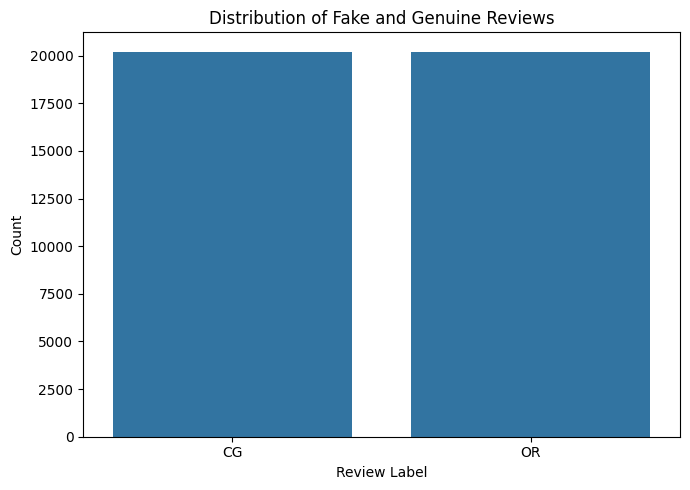

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df['label'].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='label')
plt.title("Distribution of Fake and Genuine Reviews")
plt.xlabel("Review Label")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Step 7: Class Balance Visualization
Here, we analyze the distribution of the class labels (`CG` and `OR`). Seaborn's `countplot` is used to visualize the class counts, showing a perfectly balanced dataset with exactly 20,216 records for each class.

In [ ]:
import pandas as pd

# Check original distribution
print("Original Distribution:")
print(df['label'].value_counts())

# Separate classes
label_counts = df['label'].value_counts()

# Identify both labels
label_1 = label_counts.index[0]  # The class we want to be 60%
label_2 = label_counts.index[1]  # The class we want to be 40%

# Get available counts
available_1 = label_counts[label_1]
available_2 = label_counts[label_2]

# Calculate the maximum possible size to maintain a 60:40 ratio without oversampling
# Since class 1 represents 60% and class 2 represents 40%:
# We find which class constrains us more.
limit_by_1 = int(available_1 / 0.60)
limit_by_2 = int(available_2 / 0.40)

max_total_rows = min(limit_by_1, limit_by_2)

# Calculate final counts based on this limit
count_1 = int(max_total_rows * 0.60)
count_2 = max_total_rows - count_1

# Sample rows from each class
df_1 = df[df['label'] == label_1].sample(
    n=count_1, random_state=42
)

df_2 = df[df['label'] == label_2].sample(
    n=count_2, random_state=42
)

# Combine and shuffle
df = pd.concat([df_1, df_2], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Check final distribution
print("\nFinal Shape:", df.shape)
print("\nFinal Distribution:")
print(df['label'].value_counts())

print("\nFinal Percentage:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

Original Distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64

Final Shape: (33693, 4)

Final Distribution:
label
CG    20215
OR    13478
Name: count, dtype: int64

Final Percentage:
label
CG    60.0
OR    40.0
Name: proportion, dtype: float64


### Step 8: Adjusting Class Distribution (Imbalance Setup)
This cell intentionally imbalances the dataset to set up a 60% Computer-Generated (CG) and 40% Original (OR) split. It calculates constraints to maximize data usage without oversampling, samples the rows accordingly, shuffles the final combined dataset, and prints the updated counts and percentages.

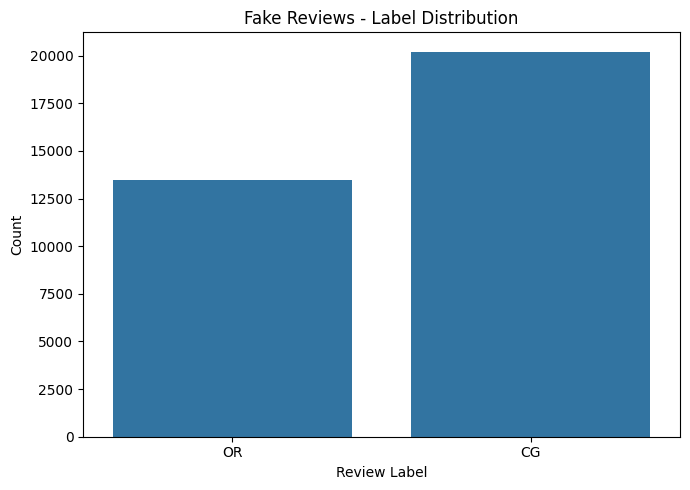

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Fake Reviews - Label Distribution")
plt.xlabel("Review Label")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### Step 9: Visualize Modified Class Count
We use a bar plot to visualize the updated class counts after the deliberate class-imbalance sampling step.

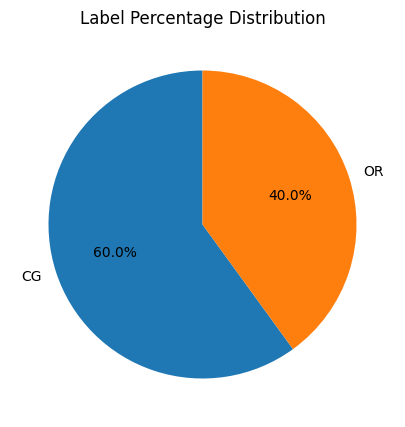

In [ ]:
label_percentage = df['label'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))

plt.pie(
    label_percentage.values,
    labels=label_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Label Percentage Distribution")
plt.show()

### Step 10: Percentage Distribution Chart
This code generates a pie chart visualizing the new label proportions (60.0% CG vs 40.0% OR) to confirm that the class rebalancing math worked successfully.

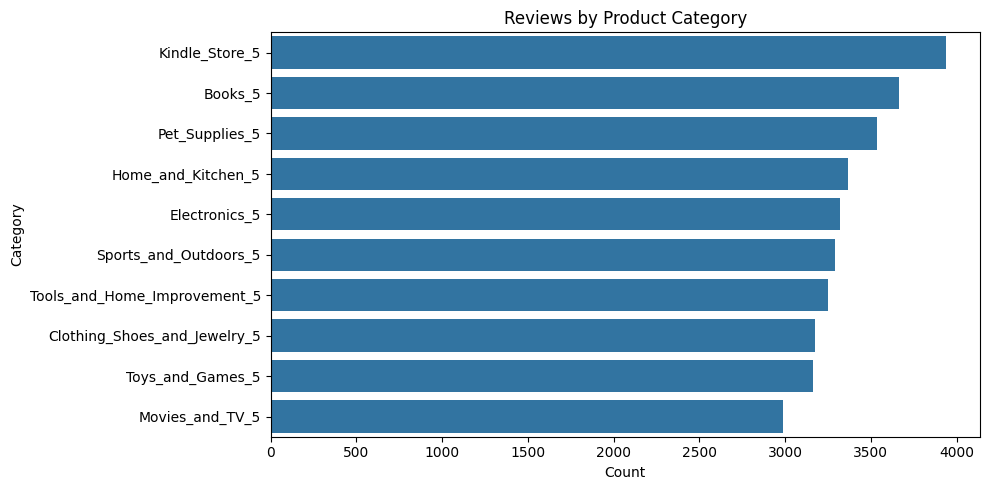

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y='category',
    order=df['category'].value_counts().index
)

plt.title("Reviews by Product Category")
plt.xlabel("Count")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

### Step 11: Distribution of Reviews by Category
Here, we plot a horizontal bar chart displaying the frequency of reviews across different product categories (e.g., Kindle Store, Books, Home and Kitchen, etc.) to understand the thematic distribution of the data.

In [ ]:
import re
import string

def clean_text(text):
    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply cleaning
df['clean_text'] = df['text_'].apply(clean_text)

# Compare original and cleaned text
print(df[['text_', 'clean_text']].head(10))

                                               text_  \
0  Super soft and fits great! I was pleasantly su...   
1  Paying for college is a pain. To help with mon...   
2  This is a slim case designed for all models of...   
3  As the Deacons of Bourbonville have been an im...   
4  My first grader has been using this toy for ab...   
5  It didn't hold my interest, but I thought it w...   
6  I can honestly say the book has kept me engage...   
7  Yo, daddio, Go Daddio!  We have the pieces we ...   
8  This has got to be one of the best wooden trai...   
9  Steamy and it really holds true. The chemistry...   

                                          clean_text  
0  super soft and fits great i was pleasantly sur...  
1  paying for college is a pain to help with mone...  
2  this is a slim case designed for all models of...  
3  as the deacons of bourbonville have been an im...  
4  my first grader has been using this toy for ab...  
5  it didnt hold my interest but i thought it was... 

### Step 12: Text Cleaning Pipeline
We define a function `clean_text` to preprocess the raw review strings. This pipeline converts text to lowercase, strips HTML tags, removes URLs, filters out punctuation, removes digits, and normalizes whitespaces. This cleaned text is stored in a new column `clean_text`.

In [ ]:
# Split text into words
df['tokens'] = df['clean_text'].apply(lambda text: text.split())

print(df[['clean_text', 'tokens']].head(10))

                                          clean_text  \
0  super soft and fits great i was pleasantly sur...   
1  paying for college is a pain to help with mone...   
2  this is a slim case designed for all models of...   
3  as the deacons of bourbonville have been an im...   
4  my first grader has been using this toy for ab...   
5  it didnt hold my interest but i thought it was...   
6  i can honestly say the book has kept me engage...   
7  yo daddio go daddio we have the pieces we need...   
8  this has got to be one of the best wooden trai...   
9  steamy and it really holds true the chemistry ...   

                                              tokens  
0  [super, soft, and, fits, great, i, was, pleasa...  
1  [paying, for, college, is, a, pain, to, help, ...  
2  [this, is, a, slim, case, designed, for, all, ...  
3  [as, the, deacons, of, bourbonville, have, bee...  
4  [my, first, grader, has, been, using, this, to...  
5  [it, didnt, hold, my, interest, but, i, though... 

### Step 13: Tokenization
This cell tokenizes our cleaned review text by splitting each string into individual words (tokens), prepping the dataset for standard NLP text manipulations.

In [ ]:
import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

df['tokens_clean'] = df['tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

print(df[['tokens', 'tokens_clean']].head(10))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


                                              tokens  \
0  [super, soft, and, fits, great, i, was, pleasa...   
1  [paying, for, college, is, a, pain, to, help, ...   
2  [this, is, a, slim, case, designed, for, all, ...   
3  [as, the, deacons, of, bourbonville, have, bee...   
4  [my, first, grader, has, been, using, this, to...   
5  [it, didnt, hold, my, interest, but, i, though...   
6  [i, can, honestly, say, the, book, has, kept, ...   
7  [yo, daddio, go, daddio, we, have, the, pieces...   
8  [this, has, got, to, be, one, of, the, best, w...   
9  [steamy, and, it, really, holds, true, the, ch...   

                                        tokens_clean  
0  [super, soft, fits, great, pleasantly, surpris...  
1  [paying, college, pain, help, money, doesnt, d...  
2  [slim, case, designed, models, ipad, mini, min...  
3  [deacons, bourbonville, important, part, histo...  
4  [first, grader, using, toy, month, loves, yet,...  
5  [didnt, hold, interest, thought, good, enough,... 

### Step 14: Stopword Removal
Using the NLTK library, we fetch standard English stopwords (common words like 'and', 'the', 'is' which carry little semantic value). We filter these out from our tokenized lists to retain only content-carrying words in `tokens_clean`.

In [ ]:
df['processed_text'] = df['tokens_clean'].apply(
    lambda words: ' '.join(words)
)

print(df[['text_', 'processed_text']].head(10))

                                               text_  \
0  Super soft and fits great! I was pleasantly su...   
1  Paying for college is a pain. To help with mon...   
2  This is a slim case designed for all models of...   
3  As the Deacons of Bourbonville have been an im...   
4  My first grader has been using this toy for ab...   
5  It didn't hold my interest, but I thought it w...   
6  I can honestly say the book has kept me engage...   
7  Yo, daddio, Go Daddio!  We have the pieces we ...   
8  This has got to be one of the best wooden trai...   
9  Steamy and it really holds true. The chemistry...   

                                      processed_text  
0  super soft fits great pleasantly surprised fit...  
1  paying college pain help money doesnt dancing ...  
2  slim case designed models ipad mini mini snaps...  
3  deacons bourbonville important part history to...  
4  first grader using toy month loves yet find is...  
5    didnt hold interest thought good enough premise 

### Step 15: Token Reconstitution
This step merges the filtered lists of cleaned tokens back into a single whitespace-separated string stored in `processed_text`.

In [ ]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

lemmatizer = WordNetLemmatizer()

# Convert POS tags for WordNet
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Lemmatization function
def lemmatize_text(words):
    tagged_words = pos_tag(words)

    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_words
    ]

# Apply lemmatization
df['lemma_tokens'] = df['tokens_clean'].apply(lemmatize_text)

# Convert list into text
df['processed_text'] = df['lemma_tokens'].apply(
    lambda words: ' '.join(words)
)

print(df[['tokens_clean', 'lemma_tokens', 'processed_text']].head(10))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


                                        tokens_clean  \
0  [super, soft, fits, great, pleasantly, surpris...   
1  [paying, college, pain, help, money, doesnt, d...   
2  [slim, case, designed, models, ipad, mini, min...   
3  [deacons, bourbonville, important, part, histo...   
4  [first, grader, using, toy, month, loves, yet,...   
5  [didnt, hold, interest, thought, good, enough,...   
6  [honestly, say, book, kept, engaged, admit, bi...   
7    [yo, daddio, go, daddio, pieces, need, kitchen]   
8  [got, one, best, wooden, trains, ever, seen, o...   
9  [steamy, really, holds, true, chemistry, two, ...   

                                        lemma_tokens  \
0  [super, soft, fit, great, pleasantly, surprise...   
1  [pay, college, pain, help, money, doesnt, danc...   
2  [slim, case, design, model, ipad, mini, mini, ...   
3  [deacon, bourbonville, important, part, histor...   
4  [first, grader, use, toy, month, love, yet, fi...   
5  [didnt, hold, interest, think, good, enough,

### Step 16: Lemmatization with POS Tagging
To standardize words to their root forms (e.g., 'running' or 'ran' becomes 'run'), we perform lemmatization. We use NLTK's `pos_tag` to determine the Part-of-Speech context of each word, translate it for WordNet, and apply the `WordNetLemmatizer` for high-quality, linguistically accurate word-reduction.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Processed Text:")
print(df['processed_text'].isnull().sum())

print("\nLabel Distribution:")
print(df['label'].value_counts())

Dataset Shape: (33693, 9)

Missing Processed Text:
0

Label Distribution:
label
CG    20215
OR    13478
Name: count, dtype: int64


### Step 17: Preprocessed Data Verification
We perform a quick sanity check to verify the final clean dataset's dimensions, check for any newly created null values in the processed text column, and confirm our target label counts.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create Label Encoder
label_encoder = LabelEncoder()

# Encode label column
df['label_encoded'] = label_encoder.fit_transform(df['label'])

# Show label mapping
for label, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(label, "=", encoded_value)

# Display data
print(df[['label', 'label_encoded']].head(10))

CG = 0
OR = 1
  label  label_encoded
0    OR              1
1    OR              1
2    OR              1
3    CG              0
4    CG              0
5    CG              0
6    CG              0
7    CG              0
8    CG              0
9    CG              0


### Step 18: Label Encoding
Machine learning models require numerical labels. We use Scikit-Learn's `LabelEncoder` to convert the string labels `CG` and `OR` into `0` and `1` respectively, printing the mapping for reference.

In [ ]:
# Input feature
X = df['processed_text']

# Target variable
y = df['label_encoded']

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSample Input:")
print(X.head())

print("\nSample Target:")
print(y.head())

Input Shape: (33693,)
Target Shape: (33693,)

Sample Input:
0    super soft fit great pleasantly surprised fit ...
1    pay college pain help money doesnt dance rathe...
2    slim case design model ipad mini mini snap pre...
3    deacon bourbonville important part history tow...
4    first grader use toy month love yet find issue...
Name: processed_text, dtype: object

Sample Target:
0    1
1    1
2    1
3    0
4    0
Name: label_encoded, dtype: int64


### Step 19: Splitting Inputs and Targets
We isolate our feature variable `X` (the preprocessed lemmatized review text) and target variable `y` (the encoded classification label) and display their structures.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Convert text into numerical features
X_tfidf = tfidf.fit_transform(df['processed_text'])

# Target variable
y = df['label_encoded']

print("TF-IDF Shape:", X_tfidf.shape)
print("Target Shape:", y.shape)

TF-IDF Shape: (33693, 10000)
Target Shape: (33693,)


### Step 20: TF-IDF Vectorization
We initialize a `TfidfVectorizer` to convert our text corpus into numerical representations. We limit our vocabulary to the top 10,000 features, use unigrams and bigrams, and filter out extremely rare or common words to build our final document-term feature matrix `X_tfidf`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Split the dataset into training and testing sets (e.g., 80% train, 20% test)
X_train_tfidf, X_test_tfidf, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Prediction
y_pred_lr = lr_model.predict(X_test_tfidf)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 89.06 %

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.93      0.91      4043
           1       0.89      0.83      0.86      2696

    accuracy                           0.89      6739
   macro avg       0.89      0.88      0.88      6739
weighted avg       0.89      0.89      0.89      6739



### Step 21: Model Selection, Split, and Training
We partition the TF-IDF feature space into training (80%) and testing (20%) splits using stratified sampling to maintain class ratios. We then initialize and train a `LogisticRegression` classifier, evaluate it on the test set, and print out accuracy alongside a comprehensive classification report containing precision, recall, and F1-score.

ROC-AUC Score: 0.9591
ROC-AUC Percentage: 95.91 %


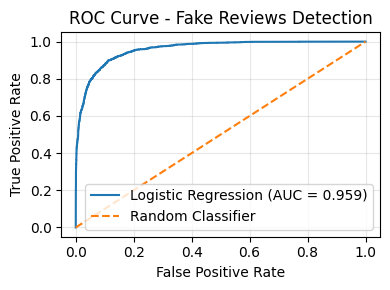

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get probability of positive class
y_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(auc_score, 4))
print("ROC-AUC Percentage:", round(auc_score * 100, 2), "%")

# Plot ROC Curve
plt.figure(figsize=(4, 3))

plt.plot(
    fpr, tpr,
    label=f'Logistic Regression (AUC = {auc_score:.3f})'
)

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fake Reviews Detection")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 22: ROC-AUC Evaluation
Using predicted class probabilities on the test set, we compute the Receiver Operating Characteristic (ROC) curve and calculate the Area Under the Curve (AUC) score to measure the model's ability to distinguish between fake and genuine reviews. We then plot the ROC curve.

In [ ]:
import joblib

# Save model, TF-IDF vectorizer and LabelEncoder
model_bundle = {
    "model": lr_model,
    "tfidf": tfidf,
    "label_encoder": label_encoder
}

joblib.dump(model_bundle, "nlp_model_bundle.joblib")

print("Model, TF-IDF and LabelEncoder saved successfully!")

Model, TF-IDF and LabelEncoder saved successfully!


### Step 23: Model Serialization
Using `joblib`, we bundle the trained Logistic Regression model, the TF-IDF vectorizer, and the Label Encoder into a single file named `nlp_model_bundle.joblib` for easy deployment and future reuse.

In [ ]:
import joblib

# Load saved model bundle
model_bundle = joblib.load("nlp_model_bundle.joblib")

# Extract saved objects
lr_model = model_bundle["model"]
tfidf = model_bundle["tfidf"]
label_encoder = model_bundle["label_encoder"]

print("Model loaded successfully!")
print("TF-IDF Vectorizer loaded successfully!")
print("Label Encoder loaded successfully!")

Model loaded successfully!
TF-IDF Vectorizer loaded successfully!
Label Encoder loaded successfully!


### Step 24: Model Loading
This cell demonstrates how to reload the saved model bundle back into memory using `joblib.load()` to simulate running predictions in a production setting.

In [ ]:
# Sample text
text = ["As the Deacons of Bourbonville have been an important part of the history of the town, the town is so close to the town, and the Deacons are there to take care of the town.\n\nThis story is a perfect story for the Deacons to learn from and learn from. The story is very quick and descriptive, and the characters are well developed. The story is told in a very believable manner, and the characters are very well developed. It's very refreshing to have a story that is about a town that has been in the news for years, and is still a great place to live.\n\nI received a copy of this book in exchange for an honest review.\n\nI received this book from the author for an honest review.I like how it is a good start to a series.  I look forward to reading more books by this author.\n\nI received this book as a gift from the author.This is the first book I've read by this author and I'm glad I did.  I loved the way she presented the story and the characters.  This book was a must read for any new re"]
# Convert text into TF-IDF features
text_tfidf = tfidf.transform(text)

# Predict encoded label
prediction = lr_model.predict(text_tfidf)

# Convert encoded label into original label
predicted_label = label_encoder.inverse_transform(
    prediction.astype(int)
)

print("Predicted Label:", predicted_label[0])

Predicted Label: CG


In [37]:
df["text_"][3]

"As the Deacons of Bourbonville have been an important part of the history of the town, the town is so close to the town, and the Deacons are there to take care of the town.\n\nThis story is a perfect story for the Deacons to learn from and learn from. The story is very quick and descriptive, and the characters are well developed. The story is told in a very believable manner, and the characters are very well developed. It's very refreshing to have a story that is about a town that has been in the news for years, and is still a great place to live.\n\nI received a copy of this book in exchange for an honest review.\n\nI received this book from the author for an honest review.I like how it is a good start to a series.  I look forward to reading more books by this author.\n\nI received this book as a gift from the author.This is the first book I've read by this author and I'm glad I did.  I loved the way she presented the story and the characters.  This book was a must read for any new r

### Step 25: Real-time Prediction Demo
We pass a custom sample review through our reloaded TF-IDF Vectorizer to extract features, feed it to the Logistic Regression model, decode the numerical prediction back into a text label, and print the model's final output (CG or OR).